In [45]:
import pandas as pd
import numpy as np
from src.adat_handling import read_adat_file
from src.dataframe_transformation import add_measure_id

In [46]:
import os
os.getcwd()

'c:\\Users\\RoeeOrland\\OneDrive - Oncohost DX\\Playground - Hub\\Roee\\bridging\\projects\\new_ANML'

In [47]:
anml_df = pd.read_csv('Reference_V4.1_Plasma_ANML.txt', sep='\t')

In [48]:
anml_df

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,2.711720,0.126547,533.096224,154.557861
1,c-Raf,10001-7,Protein,20.0,2.593482,0.100921,398.864905,100.338649
2,ZNF41,10003-15,Protein,0.5,2.220029,0.111369,169.471767,43.628502
3,ELK1,10006-25,Protein,20.0,2.799848,0.079088,638.139386,115.141731
4,GUC1A,10008-43,Protein,20.0,2.674683,0.096505,480.227476,106.589598
...,...,...,...,...,...,...,...,...
7591,ZN264,9993-11,Protein,20.0,3.026105,0.100907,1078.091795,251.736781
7592,ATP4B,9994-217,Protein,20.0,3.155992,0.129292,1466.805761,445.681061
7593,DUT,9995-6,Protein,20.0,3.132150,0.162470,1387.386809,598.492300
7594,UBXN4,9997-12,Protein,20.0,3.908458,0.159643,8206.926316,3412.255455


In [49]:
info_df = pd.read_csv('20260329_adat_data_samples_with_sample_info.csv')

In [50]:
info_df = info_df[(info_df['PlateId'].str.startswith('OH2025_05') | info_df['PlateId'].str.startswith('OH2026'))&(info_df['PlateId']!='OH2025_050')]

In [51]:
anml_qc_df = pd.read_parquet('anmlQC/v_170_OH2026_012.parquet').reset_index(drop=False)
anml_smp_df = pd.read_parquet('anmlSMP/v_262_OH2026_012.parquet').reset_index(drop=False)

In [52]:
# [col for col in anml_qc_df.columns if col.startswith('F')]

In [53]:
anml_smp_df['RowCheck'].value_counts()

RowCheck
PASS    14096
FLAG      368
Name: count, dtype: int64

In [54]:
anml_qc_df['MeasureId'] = anml_qc_df['PlateId'] + '_' + anml_qc_df['PlatePosition']

In [55]:
info_df[(info_df['SampleMatrixType']=='Streck DS2')&(info_df['SubType']=='PROPHET')]

,MeasureId,Source,IsT0,Type,SubType,DateOfRun,PlateCode,AdatFile,PlateId,ScannerID,...,ANMLFractionUsed_0_005,ANMLFractionUsed_0_5,SampleNumber,Optional1,Optional2,SysId,SysIdSource,SubjectId,Indication,SampleCollectionDate
8624,OH2025_051_A2,OH,not relevant,Sample,PROPHET,2025-11-19,OH25_051,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2025_051,SG21378706,...,0.791,0.816,9.0,ACSK382005-242689,PROPHET,NaN,NaN,NaN,NaN,NaN
8627,OH2025_051_A5,OH,not relevant,Sample,PROPHET,2025-11-19,OH25_051,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2025_051,SG21378706,...,0.813,0.826,33.0,ACSK382005-243419,PROPHET,NaN,NaN,NaN,NaN,NaN
8641,OH2025_051_D1,OH,not relevant,Sample,PROPHET,2025-11-19,OH25_051,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2025_051,SG21378706,...,0.840,0.800,4.0,ACSK382005-242674,PROPHET,NaN,NaN,NaN,NaN,NaN
8646,OH2025_051_D6,OH,not relevant,Sample,PROPHET,2025-11-19,OH25_051,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2025_051,SG21378706,...,0.829,0.809,44.0,ACSK382005-244124,PROPHET,NaN,NaN,NaN,NaN,NaN
8648,OH2025_051_E2,OH,not relevant,Sample,PROPHET,2025-11-19,OH25_051,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2025_051,SG21378706,...,0.818,0.839,13.0,ACSK382005-243045,PROPHET,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9572,OH2026_012_G2,OH,not relevant,Sample,PROPHET,2026-03-25,OH26_012,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2026_012,SG21378706,...,0.845,0.831,15.0,ACSK382005-248572,PROPHET,NaN,NaN,NaN,NaN,NaN
9574,OH2026_012_G4,OH,not relevant,Sample,PROPHET,2026-03-25,OH26_012,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2026_012,SG21378706,...,0.898,0.910,31.0,ACSK382005-248746,PROPHET,NaN,NaN,NaN,NaN,NaN
9577,OH2026_012_H1,OH,not relevant,Sample,PROPHET,2026-03-25,OH26_012,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2026_012,SG21378706,...,0.930,0.925,8.0,ACSK382005-248797,PROPHET,NaN,NaN,NaN,NaN,NaN
9579,OH2026_012_H3,OH,not relevant,Sample,PROPHET,2026-03-25,OH26_012,C:\Users\OrItzhaki\Oncohost DX/Shares - R&D/Da...,OH2026_012,SG21378706,...,0.957,0.897,24.0,ACSK382005-248927,PROPHET,NaN,NaN,NaN,NaN,NaN


In [56]:
ds_prophet_info_df = info_df[(info_df['SampleMatrixType']=='Streck DS2')&(info_df['SubType']=='PROPHET')]

In [57]:
ds_prophet_anml_qc_df = anml_qc_df[anml_qc_df['MeasureId'].isin(ds_prophet_info_df['MeasureId'])]

In [58]:
ds_prophet_anml_qc_df

,PlateId,PlateRunDate,ScannerID,PlatePosition,SlideId,Subarray,SampleId,SampleType,PercentDilution,SampleMatrix,...,PlateMatrix,experiment_date,NSCLC_model_version,RCC_model_version,MELANOMA_model_version,bridging_version,MELANOMA_PROphetScore,NSCLC_PROphetScore,RCC_PROphetScore,MeasureId
3585,OH2025_051,2025-11-19,SG21378706,A2,258736525644,1,463434142,Sample,20,Streck,...,None,None,None,None,None,None,NaN,NaN,NaN,OH2025_051_A2
3588,OH2025_051,2025-11-19,SG21378706,A5,258736525647,1,463434174,Sample,20,Streck,...,None,None,None,None,None,None,NaN,NaN,NaN,OH2025_051_A5
3602,OH2025_051,2025-11-19,SG21378706,D1,258736525643,4,463434145,Sample,20,Streck,...,None,None,None,None,None,None,NaN,NaN,NaN,OH2025_051_D1
3607,OH2025_051,2025-11-19,SG21378706,D6,258736525648,4,463424270,Sample,20,Streck,...,None,None,None,None,None,None,NaN,NaN,NaN,OH2025_051_D6
3609,OH2025_051,2025-11-19,SG21378706,E2,258736525644,5,463434185,Sample,20,Streck,...,None,None,None,None,None,None,NaN,NaN,NaN,OH2025_051_E2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8668,OH2026_012,2026-03-25,SG21378706,G2,258736527064,7,463424314,Sample,20,Streck DS2,...,EDTA PLASMA,2026-03-25,2.1,1.0,1.0,3.0,1.842105,1.842105,0.66,OH2026_012_G2
8670,OH2026_012,2026-03-25,SG21378706,G4,258736527066,7,463428176,Sample,20,Streck DS2,...,EDTA PLASMA,2026-03-25,2.1,1.0,1.0,3.0,4.342105,4.342105,6.78,OH2026_012_G4
8673,OH2026_012,2026-03-25,SG21378706,H1,258736527063,8,463424326,Sample,20,Streck DS2,...,EDTA PLASMA,2026-03-25,2.1,1.0,1.0,3.0,7.061404,7.061404,8.06,OH2026_012_H1
8675,OH2026_012,2026-03-25,SG21378706,H3,258736527065,8,463424344,Sample,20,Streck DS2,...,EDTA PLASMA,2026-03-25,2.1,1.0,1.0,3.0,6.535088,6.535088,7.00,OH2026_012_H3


In [59]:
aptamers = [col for col in ds_prophet_anml_qc_df.columns if col[0].isdigit()]

In [60]:
len(aptamers)

7596

In [61]:
ds_prophet_anml_qc_values_df = ds_prophet_anml_qc_df[aptamers]

In [117]:
ds_prophet_anml_qc_values_df

,10000-28,10001-7,10003-15,10006-25,10008-43,10010-10,10011-65,10012-5,10013-34,10014-31,...,9984-12,9986-14,9987-30,9989-12,9991-112,9993-11,9994-217,9995-6,9997-12,9999-1
3585,1383.6,702.9,194.8,1448.4,1333.7,1037.4,2687.2,2273.4,1042.2,1509.7,...,1377.1,3776.8,1044.0,915.0,1516.1,1999.3,2285.8,3159.6,12652.5,2291.2
3588,854.0,467.6,181.5,1073.0,867.6,685.8,2285.5,1458.9,658.5,1072.5,...,878.1,1484.1,677.4,682.9,733.0,1301.7,1623.8,3002.7,10167.8,11006.1
3602,1102.7,589.0,181.5,1114.0,1071.7,792.5,2215.1,2030.8,725.5,1314.0,...,1097.3,1098.0,793.1,867.5,840.3,1915.8,1944.0,2376.2,8509.6,6330.3
3607,1232.8,642.3,176.9,1124.1,1190.6,914.6,2334.1,2036.2,899.4,1292.1,...,1166.7,1718.4,969.9,825.0,1181.3,2009.8,1900.2,2293.2,16864.8,7916.6
3609,1210.0,635.3,187.0,1274.7,1213.8,847.4,2678.7,2186.4,899.6,1356.8,...,1246.8,3708.4,994.1,833.2,898.9,2020.0,2145.9,2195.9,12885.2,12680.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8668,1311.7,571.6,190.1,1181.0,1092.3,843.2,2718.2,1998.4,824.8,1298.1,...,1045.5,2532.3,1290.9,748.8,1147.8,2321.9,1890.7,2790.2,12812.1,6724.8
8670,1223.9,599.3,173.0,1254.0,1206.9,862.3,2617.9,1811.5,772.3,1275.6,...,1059.7,4283.8,1278.2,751.6,784.5,2160.8,1863.8,1589.1,7603.3,5902.5
8673,986.6,510.2,203.5,1047.8,1182.0,762.3,2539.5,1709.7,866.4,1186.8,...,2695.7,2691.9,1143.0,1157.2,9016.3,4364.9,1758.8,1199.7,4497.6,5882.6
8675,1220.2,631.4,184.3,1348.8,1229.8,950.6,3527.4,2063.0,857.5,1385.7,...,1085.9,1849.5,1357.7,790.3,837.5,2346.3,2077.7,2034.5,14492.5,10207.0


In [62]:
training_df = ds_prophet_anml_qc_values_df.iloc[:85]
test_df = ds_prophet_anml_qc_values_df.iloc[85:]

In [63]:
df_ref = anml_df

In [64]:
df_ref

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,2.711720,0.126547,533.096224,154.557861
1,c-Raf,10001-7,Protein,20.0,2.593482,0.100921,398.864905,100.338649
2,ZNF41,10003-15,Protein,0.5,2.220029,0.111369,169.471767,43.628502
3,ELK1,10006-25,Protein,20.0,2.799848,0.079088,638.139386,115.141731
4,GUC1A,10008-43,Protein,20.0,2.674683,0.096505,480.227476,106.589598
...,...,...,...,...,...,...,...,...
7591,ZN264,9993-11,Protein,20.0,3.026105,0.100907,1078.091795,251.736781
7592,ATP4B,9994-217,Protein,20.0,3.155992,0.129292,1466.805761,445.681061
7593,DUT,9995-6,Protein,20.0,3.132150,0.162470,1387.386809,598.492300
7594,UBXN4,9997-12,Protein,20.0,3.908458,0.159643,8206.926316,3412.255455


In [65]:
# df_ref = df_ref.set_index("SeqId")

In [66]:

def update_reference_from_matrix(df_ref, df_values):
    """
    Update reference statistics in df_ref using distributions from df_values.

    Parameters
    ----------
    df_ref : pd.DataFrame
        Must contain columns:
        ['SeqId', 'RefMedian', 'RefSD', 'RefLog10Median', 'RefLog10MAD']
        plus any additional metadata columns.

    df_values : pd.DataFrame
        Wide matrix where:
        - columns = SeqId
        - rows = samples (e.g., patients)
        - values = measurements

    Returns
    -------
    pd.DataFrame
        Updated df_ref with recomputed reference statistics.
    """

    # =========================
    # 1. Prepare values (handle log safety)
    # =========================

    # Replace non-positive values with NaN (to avoid log10 issues)
    df_positive = df_values.where(df_values > 0)

    # =========================
    # 2. Compute statistics per SeqId (column-wise)
    # =========================

    # Linear stats
    ref_median = df_positive.median(axis=0)
    ref_sd = df_positive.std(axis=0, ddof=1)

    # Log stats
    log_df = np.log10(df_positive)
    ref_log_median = log_df.median(axis=0)
    ref_log_mad = (log_df.sub(ref_log_median, axis=1).abs()).median(axis=0)

    # =========================
    # 3. Build new reference table
    # =========================

    df_new_ref = pd.DataFrame({
        "SeqId": df_values.columns.astype(str),
        "RefMedian": ref_median.values,
        "RefSD": ref_sd.values,
        "RefLog10Median": ref_log_median.values,
        "RefLog10MAD": ref_log_mad.values
    })

    # =========================
    # 4. Update original reference dataframe
    # =========================

    df_ref = df_ref.copy()
    df_ref_columns = df_ref.columns
    # Ensure matching types
    df_ref["SeqId"] = df_ref["SeqId"].astype(str)
    df_new_ref["SeqId"] = df_new_ref["SeqId"].astype(str)

    # Align on SeqId and update only relevant columns
    df_ref = df_ref.set_index("SeqId")
    df_new_ref = df_new_ref.set_index("SeqId")

    df_ref.update(df_new_ref)

    return df_ref.reset_index()[df_ref_columns]


In [77]:
new_ref = update_reference_from_matrix(df_ref, ds_prophet_anml_qc_values_df)
training_ref_df = update_reference_from_matrix(df_ref, training_df)
test_ref_df = update_reference_from_matrix(df_ref, test_df)

In [94]:
training_ref_df.to_csv(
    "Reference_V4.1_Plasma_ANML_STRECK_85.txt",
    sep="\t",
    index=False
)

In [122]:
new_ref.to_csv(
    "Reference_V4.1_Plasma_ANML_STRECK.txt",
    sep="\t",
    index=False
)

In [68]:
training_ref_df

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,3.067182,0.078534,1167.3,9088.946546
1,c-Raf,10001-7,Protein,20.0,2.789581,0.060254,616.0,126.660618
2,ZNF41,10003-15,Protein,0.5,2.283979,0.023908,192.3,69.229211
3,ELK1,10006-25,Protein,20.0,3.080807,0.062270,1204.5,235.596050
4,GUC1A,10008-43,Protein,20.0,3.053731,0.061580,1131.7,327.830421
...,...,...,...,...,...,...,...,...
7591,ZN264,9993-11,Protein,20.0,3.285152,0.078027,1928.2,474.053076
7592,ATP4B,9994-217,Protein,20.0,3.286322,0.045955,1933.4,908.121152
7593,DUT,9995-6,Protein,20.0,3.297038,0.100120,1981.7,1300.982969
7594,UBXN4,9997-12,Protein,20.0,3.991137,0.156386,9798.0,6075.644609


In [69]:
test_ref_df

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,3.096736,0.085589,1249.5,370.391831
1,c-Raf,10001-7,Protein,20.0,2.792252,0.062277,619.8,500.899274
2,ZNF41,10003-15,Protein,0.5,2.297542,0.038918,198.4,71.780907
3,ELK1,10006-25,Protein,20.0,3.088915,0.045592,1227.2,364.026812
4,GUC1A,10008-43,Protein,20.0,3.058502,0.072089,1144.2,317.949397
...,...,...,...,...,...,...,...,...
7591,ZN264,9993-11,Protein,20.0,3.331933,0.087928,2147.5,667.236630
7592,ATP4B,9994-217,Protein,20.0,3.285805,0.057122,1931.1,723.362540
7593,DUT,9995-6,Protein,20.0,3.280920,0.101109,1909.5,1269.325182
7594,UBXN4,9997-12,Protein,20.0,4.097889,0.187894,12528.2,8989.472929


In [71]:
import numpy as np
import pandas as pd

def symmetric_relative_difference(
    df1: pd.DataFrame,
    df2: pd.DataFrame,
    key: str = "SeqId",
    epsilon: float = 0.0,
    keep_key: bool = True,
    ) -> pd.DataFrame:
    """
    Compute symmetric relative differences between matching numeric columns
    in two dataframes:
        diff = 2 * (df1 - df2) / (df1 + df2)

    Parameters
    ----------
    df1, df2 : pd.DataFrame
        DataFrames with identical schema.
    key : str
        Column used as primary key for alignment.
    epsilon : float
        Small value added to denominator to avoid division by zero.
        If 0, will instead return NaN where denominator == 0.
    keep_key : bool
        Whether to return the key column in the output.

    Returns
    -------
    pd.DataFrame
        DataFrame of symmetric relative differences.
    """

    # --- Align on key ---
    df1_ = df1.set_index(key)
    df2_ = df2.set_index(key)

    # Ensure same ordering and matching keys
    df2_ = df2_.reindex(df1_.index)

    # --- Select numeric columns only ---
    numeric_cols = df1_.select_dtypes(include=[np.number]).columns
    df1_num = df1_[numeric_cols]
    df2_num = df2_[numeric_cols]

    # --- Compute denominator ---
    denom = df1_num + df2_num

    if epsilon > 0:
        denom = denom + epsilon
        diff = 2 * (df1_num - df2_num) / denom
    else:
        diff = 2 * (df1_num - df2_num) / denom.where(denom != 0)

    # Clean infinities (in case)
    diff = diff.replace([np.inf, -np.inf], np.nan)

    # --- Restore key if needed ---
    if keep_key:
        diff = diff.reset_index()

    return diff

In [78]:
relative_difference = symmetric_relative_difference(new_ref, training_ref_df)

<Axes: >

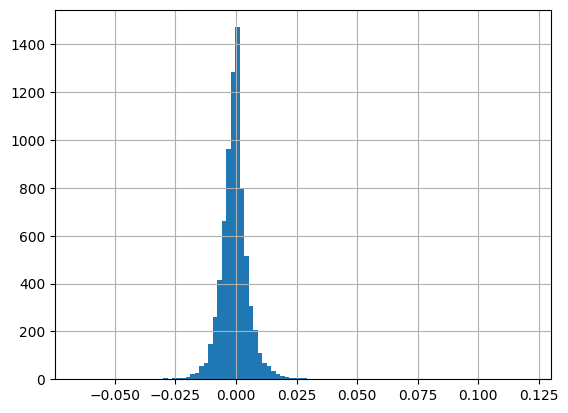

In [93]:
relative_difference['RefLog10Median'].hist(bins=100)

<Axes: >

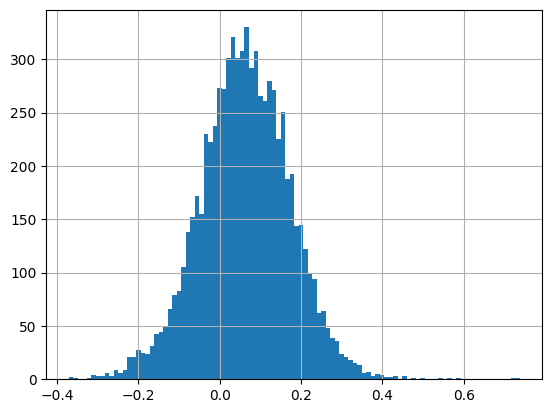

In [87]:
relative_difference['RefLog10MAD'].hist(bins=100)

In [ ]:
np.abs(np.log10(ds_prophet_anml_qc_values_df['10000-28']) - np.log10(ds_prophet_anml_qc_values_df['10000-28']).median()).median()

np.float64(0.07606814078046265)

In [88]:
new_ref

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,3.087088,0.076068,1222.05,6427.587410
1,c-Raf,10001-7,Protein,20.0,2.791268,0.061618,618.40,366.673844
2,ZNF41,10003-15,Protein,0.5,2.288473,0.029836,194.30,70.383786
3,ELK1,10006-25,Protein,20.0,3.081887,0.057822,1207.50,306.046780
4,GUC1A,10008-43,Protein,20.0,3.056636,0.068339,1139.30,322.891668
...,...,...,...,...,...,...,...,...
7591,ZN264,9993-11,Protein,20.0,3.310615,0.082737,2044.75,600.827793
7592,ATP4B,9994-217,Protein,20.0,3.286063,0.053050,1932.25,818.523933
7593,DUT,9995-6,Protein,20.0,3.295203,0.104397,1973.35,1282.766541
7594,UBXN4,9997-12,Protein,20.0,4.039741,0.164837,10958.55,7775.129954


In [70]:
df_ref

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,2.711720,0.126547,533.096224,154.557861
1,c-Raf,10001-7,Protein,20.0,2.593482,0.100921,398.864905,100.338649
2,ZNF41,10003-15,Protein,0.5,2.220029,0.111369,169.471767,43.628502
3,ELK1,10006-25,Protein,20.0,2.799848,0.079088,638.139386,115.141731
4,GUC1A,10008-43,Protein,20.0,2.674683,0.096505,480.227476,106.589598
...,...,...,...,...,...,...,...,...
7591,ZN264,9993-11,Protein,20.0,3.026105,0.100907,1078.091795,251.736781
7592,ATP4B,9994-217,Protein,20.0,3.155992,0.129292,1466.805761,445.681061
7593,DUT,9995-6,Protein,20.0,3.132150,0.162470,1387.386809,598.492300
7594,UBXN4,9997-12,Protein,20.0,3.908458,0.159643,8206.926316,3412.255455


In [124]:
ds_prophet_anml_qc_df['RowCheck'].value_counts() 

RowCheck
PASS    168
FLAG      2
Name: count, dtype: int64

In [125]:
anml_smp_df['MeasureId'] = anml_smp_df['PlateId'] + '_' + anml_smp_df['PlatePosition']
ds_prophet_anml_smp_df = anml_smp_df[anml_smp_df['MeasureId'].isin(ds_prophet_info_df['MeasureId'])]

In [126]:
ds_prophet_anml_smp_df['RowCheck'].value_counts()

RowCheck
PASS    153
FLAG     17
Name: count, dtype: int64

In [25]:
import os
import re
import pandas as pd

def load_and_concat_adats(base_folder: str, pattern: str) -> pd.DataFrame:
    """
    Recursively search for CSV files whose filenames match a regex pattern,
    load them into pandas DataFrames, and concatenate them.

    Parameters
    ----------
    base_folder : str
        Path to the main folder containing subfolders with ADAT files.
    pattern : str
        Regex pattern to match filenames (e.g., r'\\d\\.csv').

    Returns
    -------
    pd.DataFrame
        Concatenated DataFrame of all matching ADAT files.
        Returns empty DataFrame if no matches found.
    """
    dfs = []
    regex = re.compile(pattern)

    for root, _, files in os.walk(base_folder):
        for file in files:
            if regex.search(file):
                file_path = os.path.join(root, file)
                try:
                    df, _ = read_adat_file(file_path)
                    # df["source_file"] = file  # optional but useful
                    print(file)
                    dfs.append(add_measure_id(df))
                except Exception as e:
                    print(f"Skipping {file_path}: {e}")

    if dfs:
        return pd.concat(dfs, ignore_index=True)
    else:
        return pd.DataFrame()

In [95]:
adat_df = load_and_concat_adats('./results', 'anmlSMP.adat')

c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_051.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_052.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


...

OH2026_007.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_008.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_009.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


In [98]:
adat_df[adat_df['MeasureId'].isin(ds_prophet_anml_qc_df['MeasureId'])]['RowCheck'].value_counts()

RowCheck
PASS    118
FLAG      2
Name: count, dtype: int64

## Half and half training/testing

In [129]:
training_qc_df = ds_prophet_anml_qc_df.iloc[:85, :]
testing_qc_df = ds_prophet_anml_qc_df.iloc[85:, :]

In [ ]:
training_qc_df

# Compare to Izhar

In [7]:
os.listdir('results/roee_lot_1')

['OH2025_051']

In [2]:
roee_051, _  = read_adat_file('results/roee_lot_1/OH2025_051/OH2025_051.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat')

c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


In [3]:
aptamers = [col for col in roee_051.columns if col[0].isdigit()]

In [4]:
roee_051[aptamers]

,10000-28,10001-7,10003-15,10006-25,10008-43,10010-10,10011-65,10012-5,10013-34,10014-31,...,9984-12,9986-14,9987-30,9989-12,9991-112,9993-11,9994-217,9995-6,9997-12,9999-1
0,1097.8,832.1,192.9,1018.2,882.9,612.1,4454.5,2777.7,833.3,1571.2,...,1166.1,1567.4,994.2,866.9,746.8,1996.2,2869.3,3898.2,70604.6,7651.2
1,1132.3,575.2,164.3,1185.3,1091.4,849.0,2199.1,1860.5,852.9,1235.5,...,1127.0,3090.8,854.4,748.8,1240.7,1636.1,1870.6,2585.7,10354.3,1875.0
2,219.6,185.7,142.2,174.6,210.5,212.0,495.8,438.0,169.1,439.0,...,372.4,109.3,178.5,375.6,87.6,360.2,704.7,462.5,125.4,175.0
3,943.0,511.4,142.3,1122.4,961.5,614.2,4377.3,19800.6,929.5,1670.4,...,1234.1,9703.1,1415.4,747.5,1165.4,2163.8,2997.0,3432.6,10138.9,3385.0
4,1048.3,574.0,191.9,1317.1,1065.0,841.8,2805.5,1790.8,808.3,1316.5,...,1077.9,1821.7,831.5,838.3,899.8,1597.8,1993.2,3685.8,12481.0,13510.0
5,869.5,375.9,209.9,771.9,650.2,612.0,3772.2,1917.0,693.5,1399.3,...,794.3,4584.3,1149.5,615.8,1736.3,1749.8,2283.9,2335.4,6679.0,1815.5
6,841.4,381.5,200.6,827.0,661.9,604.8,3527.3,1839.9,636.6,1378.6,...,791.1,4557.1,1015.2,650.9,1580.5,1698.7,2193.2,2334.2,7373.9,1809.5
7,974.7,621.5,175.3,1219.7,856.3,598.9,4374.6,2581.7,874.4,1418.3,...,1067.7,12230.7,903.7,836.1,1856.5,1917.6,2407.8,3238.8,20683.1,4099.9
8,1034.7,510.9,180.9,978.3,939.4,637.0,4550.5,2848.3,901.2,1655.2,...,1262.3,3073.8,934.7,879.6,801.6,2428.5,4073.9,4535.0,16259.6,2706.1
9,1268.4,1459.1,149.7,1381.9,803.5,553.7,4929.1,3096.4,881.2,1749.6,...,1564.7,2610.1,1098.3,729.4,1062.0,2504.7,2866.5,10367.2,45198.5,15963.0


In [22]:
roee_012, _  = read_adat_file('results/roee/OH2026_012/OH2026_012.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat')
izhar_012, _  = read_adat_file('results/izhar/OH2026_012/OH2026_012.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat') #hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat')

c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')
c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


In [23]:
roee_012[aptamers].compare(izhar_012[aptamers])

Empty DataFrame
Columns: []
Index: []

In [28]:
roee_results = load_and_concat_adats('./results/roee', 'anmlSMP.adat')

c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_051.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_052.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


...

OH2026_010.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_011.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_012.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


In [29]:
roee_results.shape

(960, 7634)

In [35]:
izhar_results = load_and_concat_adats('./results/izhar', 'anmlSMP.adat')

c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_051.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_052.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


...

OH2026_010.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_011.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_012.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


In [36]:
izhar_results.shape

(960, 7634)

In [37]:
roee_results[aptamers].compare(izhar_results[aptamers])

Empty DataFrame
Columns: []
Index: []

# Comparing reference values

In [39]:
lot_1_reference = pd.read_csv('references/7KL1/plasma/Reference_V4.1_Plasma_ANML.txt', sep='\t')
lot_3_reference = pd.read_csv('references/7KL3/plasma/Reference_V4.1_Plasma_ANML.txt', sep='\t')

In [40]:
lot_1_reference.head()

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,2.711720,0.126547,533.096224,154.557861
1,c-Raf,10001-7,Protein,20.0,2.593482,0.100921,398.864905,100.338649
2,ZNF41,10003-15,Protein,0.5,2.220029,0.111369,169.471767,43.628502
3,ELK1,10006-25,Protein,20.0,2.799848,0.079088,638.139386,115.141731
4,GUC1A,10008-43,Protein,20.0,2.674683,0.096505,480.227476,106.589598


In [41]:
lot_3_reference.head()

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,2.711720,0.126547,533.096224,154.557861
1,c-Raf,10001-7,Protein,20.0,2.593482,0.100921,398.864905,100.338649
2,ZNF41,10003-15,Protein,0.5,2.220029,0.111369,169.471767,43.628502
3,ELK1,10006-25,Protein,20.0,2.799848,0.079088,638.139386,115.141731
4,GUC1A,10008-43,Protein,20.0,2.674683,0.096505,480.227476,106.589598


In [42]:
lot_3_reference.compare(lot_1_reference)

Empty DataFrame
Columns: []
Index: []

In [43]:
lot_1_reference.describe()

,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
count,7596.000000,7596.000000,7596.000000,7596.000000,7596.000000
mean,16.549036,3.053514,0.142789,3366.861710,1325.546080
std,7.460774,0.557279,0.052548,10538.551344,4082.895292
min,0.000000,0.252349,0.006456,1.788640,0.684767
25%,20.000000,2.664051,0.111030,472.053241,130.941184
50%,20.000000,2.977030,0.131301,962.570387,316.975054
75%,20.000000,3.358748,0.161465,2308.008568,905.284055
max,20.000000,5.366161,0.889891,233172.637598,148516.925470


In [44]:
lot_3_reference.describe()

,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
count,7596.000000,7596.000000,7596.000000,7596.000000,7596.000000
mean,16.549036,3.053514,0.142789,3366.861710,1325.546080
std,7.460774,0.557279,0.052548,10538.551344,4082.895292
min,0.000000,0.252349,0.006456,1.788640,0.684767
25%,20.000000,2.664051,0.111030,472.053241,130.941184
50%,20.000000,2.977030,0.131301,962.570387,316.975054
75%,20.000000,3.358748,0.161465,2308.008568,905.284055
max,20.000000,5.366161,0.889891,233172.637598,148516.925470


# 85

In [95]:
os.getcwd()

'c:\\Users\\RoeeOrland\\OneDrive - Oncohost DX\\Playground - Hub\\Roee\\bridging\\projects\\new_ANML'

In [96]:
roee_85 = load_and_concat_adats('results/roee/85', 'anmlSMP.adat')

c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_051.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2025_052.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


...

OH2026_010.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_011.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


c:\Users\RoeeOrland\OneDrive - Oncohost DX\Playground - Hub\Roee\bridging\bridging_env\Lib\site-packages\somadata\io\adat\file.py:149: UserWarning: Adding empty values to column metadata: "SeqIdVersion"
  warnings.warn(f'Adding empty values to column metadata: "{name}"')


OH2026_012.hybNorm.medNormInt.plateScale.calibrate.anmlQC.qcCheck.anmlSMP.adat
Added MeasureId


In [97]:
roee_85['RowCheck'].value_counts()

RowCheck
PASS    888
FLAG     72
Name: count, dtype: int64

In [98]:
roee_85 = add_measure_id(roee_85)

No need to add MeasureId


In [99]:
ds_prophet_info_df['MeasureId']

8624    OH2025_051_A2
8627    OH2025_051_A5
8641    OH2025_051_D1
8646    OH2025_051_D6
8648    OH2025_051_E2
            ...      
9572    OH2026_012_G2
9574    OH2026_012_G4
9577    OH2026_012_H1
9579    OH2026_012_H3
9582    OH2026_012_H6
Name: MeasureId, Length: 170, dtype: object

In [100]:
roee_85[roee_85['MeasureId'].isin(ds_prophet_info_df['MeasureId'])]['RowCheck'].value_counts()

RowCheck
PASS    168
FLAG      2
Name: count, dtype: int64

In [103]:
training_df

,10000-28,10001-7,10003-15,10006-25,10008-43,10010-10,10011-65,10012-5,10013-34,10014-31,...,9984-12,9986-14,9987-30,9989-12,9991-112,9993-11,9994-217,9995-6,9997-12,9999-1
3585,1383.6,702.9,194.8,1448.4,1333.7,1037.4,2687.2,2273.4,1042.2,1509.7,...,1377.1,3776.8,1044.0,915.0,1516.1,1999.3,2285.8,3159.6,12652.5,2291.2
3588,854.0,467.6,181.5,1073.0,867.6,685.8,2285.5,1458.9,658.5,1072.5,...,878.1,1484.1,677.4,682.9,733.0,1301.7,1623.8,3002.7,10167.8,11006.1
3602,1102.7,589.0,181.5,1114.0,1071.7,792.5,2215.1,2030.8,725.5,1314.0,...,1097.3,1098.0,793.1,867.5,840.3,1915.8,1944.0,2376.2,8509.6,6330.3
3607,1232.8,642.3,176.9,1124.1,1190.6,914.6,2334.1,2036.2,899.4,1292.1,...,1166.7,1718.4,969.9,825.0,1181.3,2009.8,1900.2,2293.2,16864.8,7916.6
3609,1210.0,635.3,187.0,1274.7,1213.8,847.4,2678.7,2186.4,899.6,1356.8,...,1246.8,3708.4,994.1,833.2,898.9,2020.0,2145.9,2195.9,12885.2,12680.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8365,1308.2,633.6,195.0,1204.5,1189.7,796.1,2773.6,2043.1,746.7,1332.7,...,1083.7,2057.1,1225.3,721.6,973.8,2311.9,1996.3,2447.0,7333.2,6067.1
8367,836.5,443.0,176.3,936.5,816.9,591.9,2038.7,1413.3,527.2,991.9,...,750.4,1977.3,1002.3,588.5,1544.6,1525.1,1518.7,1473.3,6724.7,7574.6
8378,1255.4,648.9,234.0,1393.9,1193.6,872.7,2825.7,2075.2,827.9,1404.9,...,1081.8,3607.8,1327.3,754.6,1118.3,2195.4,1934.2,2113.5,15848.8,9002.9
8380,816.4,478.4,155.7,986.9,790.2,598.3,2228.7,1349.4,558.0,1005.6,...,714.2,2219.3,1011.6,568.7,528.4,1334.8,1435.1,1427.4,9385.0,3910.8


In [105]:
ds_prophet_anml_qc_df['PlateId'].value_counts()

PlateId
OH2026_012    17
OH2026_011    17
OH2026_010    16
OH2026_009    15
OH2025_054    14
OH2026_007    12
OH2026_006    10
OH2025_055    10
OH2025_051     9
OH2025_053     9
OH2025_056     7
OH2026_005     6
OH2026_008     6
OH2026_002     5
OH2025_057     5
OH2025_052     4
OH2026_003     3
OH2026_004     3
OH2026_001     2
Name: count, dtype: int64

In [ ]:
Overall DS2 from plates OH2025_051-OH2026_012: 170 samples from 19 plates
When bridging according to all 170 samples we have 2 flagged samples out of the entire 170 sample cohort.
When using half the samples for bridging: this bridging is based on 85 samples from the first 13 plates (OH2025_051-OH2026_006). Using this bridging we still arrive at the same 2/170 flag ratio across all 19 plates.
Note that since plates OH2025_051-OH2026_005 are based on Lot1, while the second half is almost completely based on Lot3, 
    
    

In [115]:
ds_prophet_anml_qc_df.iloc[85:, :]['Optional1'].value_counts()

Optional1
ACSK382005-248594    2
ACSK382005-244422    2
ACSK382005-248794    2
ACSK382005-244103    2
ACSK382005-242949    2
                    ..
ACSK382005-248572    1
ACSK382005-248746    1
ACSK382005-248797    1
ACSK382005-248927    1
ACSK382005-244212    1
Name: count, Length: 79, dtype: int64

In [121]:
anml_smp_df['MeasureId'] = anml_smp_df['PlateId'] + '_' + anml_smp_df['PlatePosition']

In [122]:
anml_smp_df[anml_smp_df['MeasureId'].isin(ds_prophet_anml_qc_df.iloc[:85, :]['MeasureId'])]['RowCheck'].value_counts()

RowCheck
PASS    79
FLAG     6
Name: count, dtype: int64

In [123]:
anml_smp_df[anml_smp_df['MeasureId'].isin(ds_prophet_anml_qc_df.iloc[85:, :]['MeasureId'])]['RowCheck'].value_counts()

RowCheck
PASS    74
FLAG    11
Name: count, dtype: int64

In [124]:
anml_df.head(1)

,Target,SeqId,Type,Dilution,RefLog10Median,RefLog10MAD,RefMedian,RefSD
0,CRBB2,10000-28,Protein,20.0,2.71172,0.126547,533.096224,154.557861


In [128]:
anml_df[anml_df['Type']=='Hybridization Control Elution']['Dilution']

3358    0.0
3408    0.0
3477    0.0
3589    0.0
3642    0.0
3709    0.0
3765    0.0
3818    0.0
3819    0.0
4049    0.0
4194    0.0
4488    0.0
Name: Dilution, dtype: float64

In [127]:
anml_df['Dilution'].value_counts()

Dilution
20.000    6257
0.500     1131
0.005      196
0.000       12
Name: count, dtype: int64

For each protein we have the following columns: 
    Target: protein name
    SeqId: aptamer Seq Id
    Type: 

In [ ]:
For each aptamer we have the following columns: 
    Target: target protein name
    Type: Protein, NonHuman, Spuriomer, Hybridization Control Elution, Non-Biotin, Non-Cleavable, Spurimer
    Dilution: 20.0, 0.5, 0.005, 0.0 (for hybrdization control elution aptamers)
    "RefLog10Median": the median of the aptamer's Log10 RFU across the reference samples
    "RefLog10MAD": the median absolute deviation of the aptamer's Log10 RFU across the reference samples. 
    "RefMedian": the median of the aptamer's RFU across the reference samples
    "RefSD": the standard deviation of the aptamer's RFU across the reference samples

SyntaxError: unterminated string literal (detected at line 5) (4284395583.py, line 5)